In [17]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import dlib

from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, classification_report,
)

from src.preprocess import preprocess_kdef_image

## 3.1 Data loading and preprocessing


In [18]:
EMOTIONS = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
}

KDEF_TO_FER = {
    "angry": 0, "disgust": 1, "afraid": 2, "happy": 3,
    "sad": 4, "surprise": 5, "neutral": 6,
}

emotionDict = {
    0: 'Angry', 1: 'Disgust', 2: 'Fear', 3: 'Happy',
    4: 'Sad', 5: 'Surprise', 6: 'Neutral',
}
class_names = [emotionDict[i] for i in range(7)]

ROOT = Path("data/KDEF_and_AKDEF/KDEF/")

records = []
for img_path in ROOT.rglob("*.JPG"):
    stem = img_path.stem
    
    for emotion_code in EMOTIONS:
        # Frontal images only: pose code "S" (straight)
        if stem[4:] == emotion_code + "S":
            records.append({
                "path": str(img_path),
                "subject": stem[1:4],
                "emotion": EMOTIONS[emotion_code],
            })
            
            break

kdef_df = pd.DataFrame(records)
print("Frontal KDEF images:", len(kdef_df), "from", kdef_df["subject"].nunique(), "subjects")

Frontal KDEF images: 980 from 70 subjects


In [19]:
X_kdef_img, y_kdef, groups_kdef = [], [], []

for _, row in kdef_df.iterrows():
    try:
        img = preprocess_kdef_image(row["path"])
    except ValueError as e:
        print("Skipped:", e)
        continue

    X_kdef_img.append(img * 255.0)
    y_kdef.append(KDEF_TO_FER[row["emotion"]])
    groups_kdef.append(row["subject"])

X_kdef_img = np.array(X_kdef_img)
y_kdef = np.array(y_kdef)
groups_kdef = np.array(groups_kdef)

print("KDEF:", X_kdef_img.shape)

KDEF: (980, 48, 48)


## 3.2 Load test set of FER2013

In [20]:
fer_test = pd.read_csv("./data/fer2013_test.csv")

X_fer_img = np.array(
    [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in fer_test['pixels']])

y_fer = fer_test['emotion'].values

print("FER2013 test:", X_fer_img.shape)
print(pd.Series(y_fer).map(emotionDict).value_counts())

FER2013 test: (3589, 48, 48)
Happy       879
Neutral     626
Sad         594
Fear        528
Angry       491
Surprise    416
Disgust      55
Name: count, dtype: int64


## 3.3 Domain Shift analysis: Dataset comparison

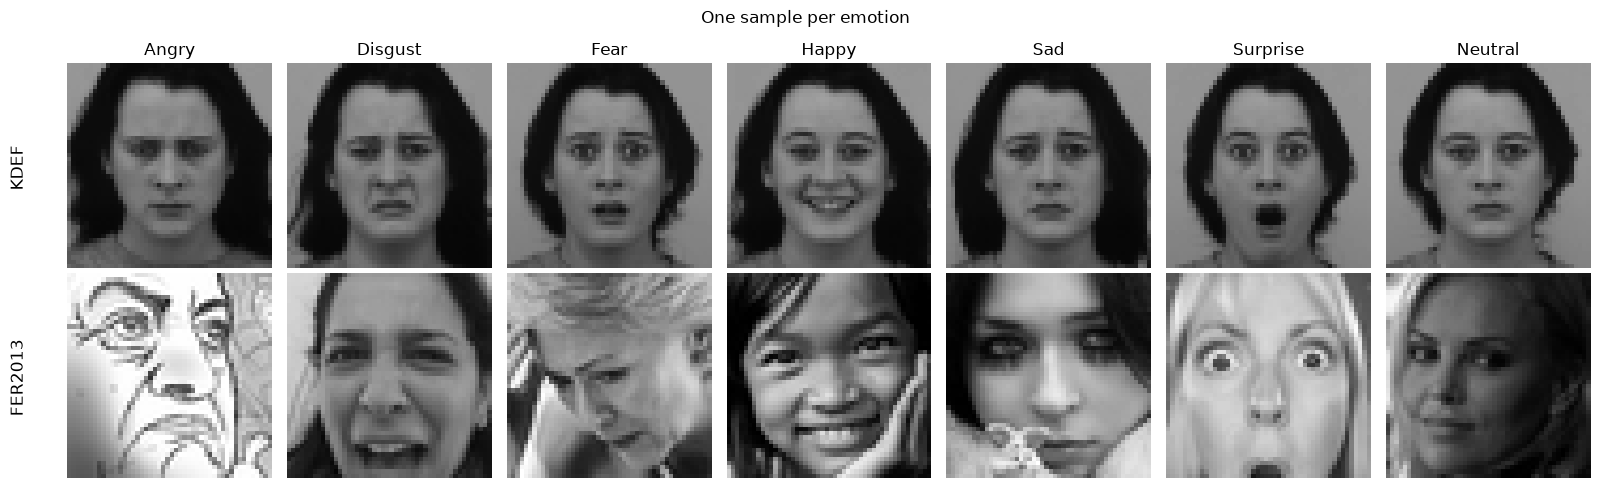

In [21]:
fig, axes = plt.subplots(2, 7, figsize=(16, 5))

INDEX = 13

for c in range(7):
    k = np.where(y_kdef == c)[0][INDEX]
    f = np.where(y_fer == c)[0][INDEX]
    
    axes[0, c].imshow(X_kdef_img[k], cmap="gray", vmin=0, vmax=255)
    axes[1, c].imshow(X_fer_img[f], cmap="gray", vmin=0, vmax=255)
    axes[0, c].set_title(emotionDict[c])
    axes[0, c].axis("off")
    axes[1, c].axis("off")

axes[0, 0].text(-10, 24, "KDEF", rotation=90, va="center", ha="right", fontsize=12)
axes[1, 0].text(-10, 24, "FER2013", rotation=90, va="center", ha="right", fontsize=12)

plt.suptitle("One sample per emotion")
plt.tight_layout()
plt.show()

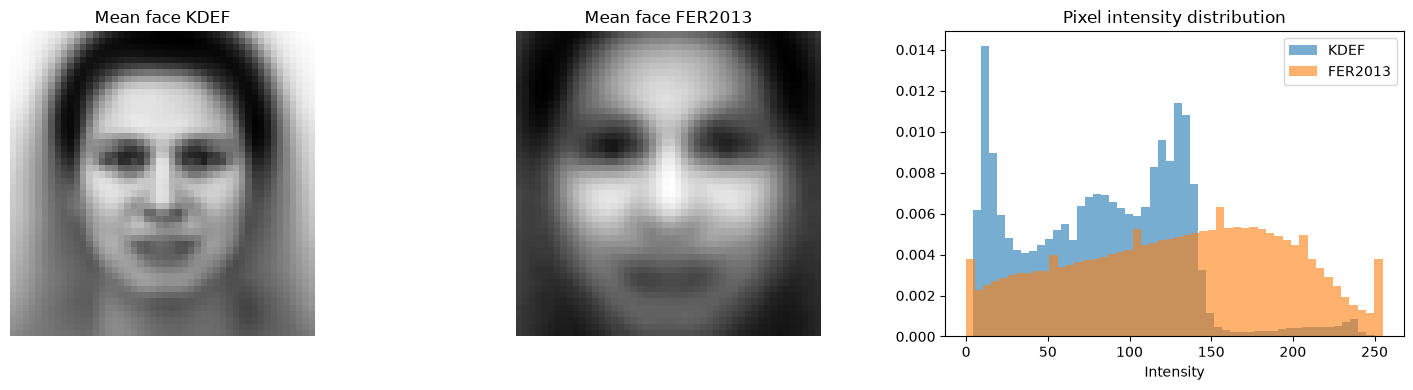

KDEF    mean 83.3  std 49.4
FER2013 mean 129.1  std 65.4


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(X_kdef_img.mean(axis=0), cmap="gray")
axes[0].set_title("Mean face KDEF")
axes[0].axis("off")

axes[1].imshow(X_fer_img.mean(axis=0), cmap="gray")
axes[1].set_title("Mean face FER2013")
axes[1].axis("off")

axes[2].hist(X_kdef_img.ravel(), bins=50, density=True, alpha=0.6, label="KDEF")
axes[2].hist(X_fer_img.ravel(), bins=50, density=True, alpha=0.6, label="FER2013")
axes[2].set_title("Pixel intensity distribution")
axes[2].set_xlabel("Intensity")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"KDEF    mean {X_kdef_img.mean():.1f}  std {X_kdef_img.std():.1f}")
print(f"FER2013 mean {X_fer_img.mean():.1f}  std {X_fer_img.std():.1f}")

## 3.4 Feature extraction

In [23]:
def extractHOG(images):
    hog_features = []
    
    for img in images:
        features = hog(
            img,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys'
        )
    
        hog_features.append(features)
    return np.array(hog_features)


landmDet = dlib.shape_predictor("faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat")


def extractLandmarksFER(images):
    face_rects = dlib.rectangle(left=1, top=1, right=47, bottom=47)
    x1 = face_rects.left()
    y1 = face_rects.top()
    x2 = face_rects.right()
    y2 = face_rects.bottom()

    landm = []
    for img in images:
        # Adaptation: dlib needs uint8 images
        la = landmDet(img.astype(np.uint8), face_rects)

        la2 = np.asarray(np.matrix([
            [
                (p.x - 0.5 * (x2 - x1)) / (x2 - x1), (p.y - 0.5 * (y2 - y1)) / (y2 - y1)
            ] for p in la.parts()])).astype(np.float32)
        la2 -= np.mean(la2, axis=0, keepdims=True)
        la2 /= np.max(np.abs(la2), axis=0, keepdims=True)

        landm.append(la2.flatten())
    return np.stack(landm)


# PCA is fitted on KDEF only: FER2013 must stay unseen
pca = PCA(n_components=0.95, random_state=42)
pca.fit(X_kdef_img.reshape(len(X_kdef_img), -1))

features = {
    "HOG": (extractHOG(X_kdef_img), extractHOG(X_fer_img)),
    "Landmarks": (extractLandmarksFER(X_kdef_img), extractLandmarksFER(X_fer_img)),
    "PCA": (pca.transform(X_kdef_img.reshape(len(X_kdef_img), -1)),
            pca.transform(X_fer_img.reshape(len(X_fer_img), -1))),
}

for name, (Xk, Xf) in features.items():
    print(f"{name:10s} KDEF {Xk.shape}  FER2013 {Xf.shape}")

HOG        KDEF (980, 900)  FER2013 (3589, 900)
Landmarks  KDEF (980, 136)  FER2013 (3589, 136)
PCA        KDEF (980, 72)  FER2013 (3589, 72)


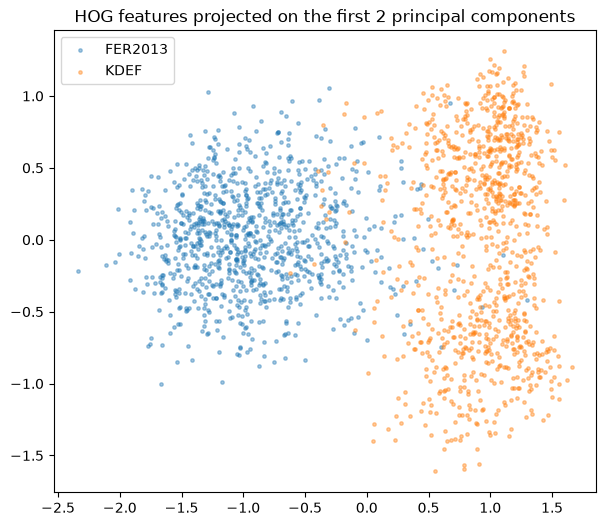

In [24]:
# 2D view of the HOG feature space: if both datasets overlapped, there would be no domain shift
rng = np.random.default_rng(42)
fer_sample = rng.choice(len(X_fer_img), size=len(X_kdef_img), replace=False)

hog_k, hog_f = features["HOG"]
proj = PCA(n_components=2, random_state=42).fit(np.vstack([hog_k, hog_f[fer_sample]]))

pk = proj.transform(hog_k)
pf = proj.transform(hog_f[fer_sample])

plt.figure(figsize=(7, 6))
plt.scatter(pf[:, 0], pf[:, 1], s=6, alpha=0.4, label="FER2013")
plt.scatter(pk[:, 0], pk[:, 1], s=6, alpha=0.4, label="KDEF")
plt.title("HOG features projected on the first 2 principal components")
plt.legend()
plt.show()

## 3.5 Retraining of best model Task 2

In [25]:
def make_model(classifier, feature):
    # Same configurations as Tasks 1 and 2
    if classifier == "Random Forest":
        return RandomForestClassifier(
            n_estimators=300,
            max_depth=11,
            max_features='sqrt',
            random_state=42,
            n_jobs=-1,
            criterion="entropy"
        )
    if classifier == "SVM":
        svm = SVC(kernel='rbf', random_state=42)
        return make_pipeline(StandardScaler(), svm) if feature == "PCA" else svm
    if classifier == "Logistic Regression":
        lr = LogisticRegression(max_iter=1000, random_state=42)
        return lr if feature == "Landmarks" else make_pipeline(StandardScaler(), lr)


def scores(y, y_pred):
    return {
        "Accuracy": accuracy_score(y, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y, y_pred),
        "Macro F1": f1_score(y, y_pred, average='macro'),
    }


def show_confusion(y, y_pred, title):
    conf_matrix = confusion_matrix(y, y_pred, labels=range(7), normalize="true")
    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(f"figures/{title}.png")
    plt.show()

=== Random Forest + HOG: trained on KDEF, tested on FER2013 ===
Accuracy: 0.21
Balanced accuracy: 0.20
Macro F1: 0.16
              precision    recall  f1-score   support

       Angry       0.19      0.05      0.07       491
     Disgust       0.04      0.09      0.06        55
        Fear       0.14      0.16      0.15       528
       Happy       0.41      0.32      0.36       879
         Sad       0.17      0.20      0.18       594
    Surprise       0.18      0.57      0.27       416
     Neutral       0.27      0.01      0.02       626

    accuracy                           0.21      3589
   macro avg       0.20      0.20      0.16      3589
weighted avg       0.24      0.21      0.19      3589

Predicted class distribution:
Angry        124
Disgust      114
Fear         623
Happy        681
Sad          702
Surprise    1315
Neutral       30


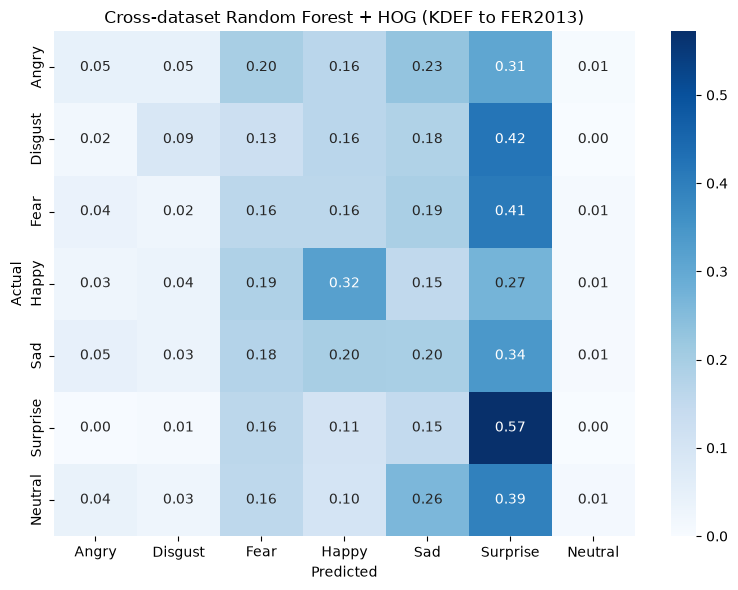

=== SVM + HOG: trained on KDEF, tested on FER2013 ===
Accuracy: 0.21
Balanced accuracy: 0.21
Macro F1: 0.18
              precision    recall  f1-score   support

       Angry       0.16      0.40      0.23       491
     Disgust       0.02      0.18      0.04        55
        Fear       0.15      0.07      0.09       528
       Happy       0.66      0.20      0.31       879
         Sad       0.19      0.30      0.24       594
    Surprise       0.32      0.32      0.32       416
     Neutral       0.20      0.00      0.00       626

    accuracy                           0.21      3589
   macro avg       0.24      0.21      0.18      3589
weighted avg       0.31      0.21      0.20      3589

Predicted class distribution:
Angry       1220
Disgust      472
Fear         254
Happy        267
Sad          946
Surprise     425
Neutral        5


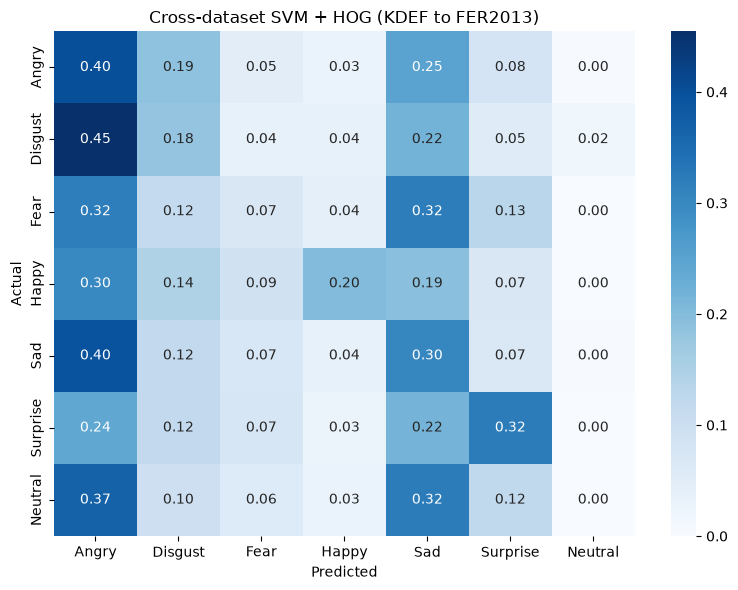

In [26]:
Xk, Xf = features["HOG"]

for classifier in ["Random Forest", "SVM"]:
    model = make_model(classifier, "HOG")
    model.fit(Xk, y_kdef)
    y_pred = model.predict(Xf)

    s = scores(y_fer, y_pred)
    print(f"=== {classifier} + HOG: trained on KDEF, tested on FER2013 ===")
    print(f"Accuracy: {s['Accuracy']:.2f}")
    print(f"Balanced accuracy: {s['Balanced accuracy']:.2f}")
    print(f"Macro F1: {s['Macro F1']:.2f}")
    print(classification_report(y_fer, y_pred, labels=range(7), target_names=class_names, zero_division=0))
    print("Predicted class distribution:")
    print(pd.Series(y_pred).map(emotionDict).value_counts().reindex(class_names, fill_value=0).to_string())
    show_confusion(y_fer, y_pred, f"Cross-dataset {classifier} + HOG (KDEF to FER2013)")

## 3.6 Feature Transfer

In [27]:
cv = GroupKFold(n_splits=5)
rows = []

for feature, (Xk, Xf) in features.items():
    for classifier in ["Random Forest", "SVM", "Logistic Regression"]:
        in_pred = cross_val_predict(
            make_model(classifier, feature), Xk, y_kdef, groups=groups_kdef, cv=cv)
        
        f1_in = f1_score(y_kdef, in_pred, average='macro')
        model = make_model(classifier, feature).fit(Xk, y_kdef)
        cross = scores(y_fer, model.predict(Xf))

        rows.append({
            "Features": feature,
            "Classifier": classifier,
            "In-domain macro F1 (KDEF CV)": f1_in,
            "Cross accuracy (FER2013)": cross["Accuracy"],
            "Cross balanced acc. (FER2013)": cross["Balanced accuracy"],
            "Cross macro F1 (FER2013)": cross["Macro F1"],
            "Retained": cross["Macro F1"] / f1_in,
        })

transfer = pd.DataFrame(rows).set_index(["Features", "Classifier"])
transfer.round(2)

In-domain macro F1 (KDEF CV)  \
Features  Classifier                                          
HOG       Random Forest                                0.61   
          SVM                                          0.64   
          Logistic Regression                          0.61   
Landmarks Random Forest                                0.51   
          SVM                                          0.41   
          Logistic Regression                          0.49   
PCA       Random Forest                                0.54   
          SVM                                          0.68   
          Logistic Regression                          0.58   

                               Cross accuracy (FER2013)  \
Features  Classifier                                      
HOG       Random Forest                            0.21   
          SVM                                      0.21   
          Logistic Regression                      0.25   
Landmarks Random Forest                            0.29   
          SVM                                      0.26   
          Logistic Regression                      0.31   
PCA       Random Forest                            0.16   
          SVM                                      0.07   
          Logistic Regression                      0.17   

                               Cross balanced acc. (FER2013)  \
Features  Classifier                                           
HOG       Random Forest                                 0.20   
          SVM                                           0.21   
          Logistic Regression                           0.23   
Landmarks Random Forest                                 0.25   
          SVM                                           0.24   
          Logistic Regression                           0.29   
PCA       Random Forest                                 0.16   
          SVM                                           0.14   
          Logistic Regression                           0.16   

                               Cross macro F1 (FER2013)  Retained  
Features  Classifier                                               
HOG       Random Forest                            0.16      0.26  
          SVM                                      0.18      0.27  
          Logistic Regression                      0.20      0.32  
Landmarks Random Forest                            0.25      0.49  
          SVM                                      0.21      0.52  
          Logistic Regression                      0.26      0.52  
PCA       Random Forest                            0.13      0.25  
          SVM                                      0.07      0.10  
          Logistic Regression                      0.14      0.25

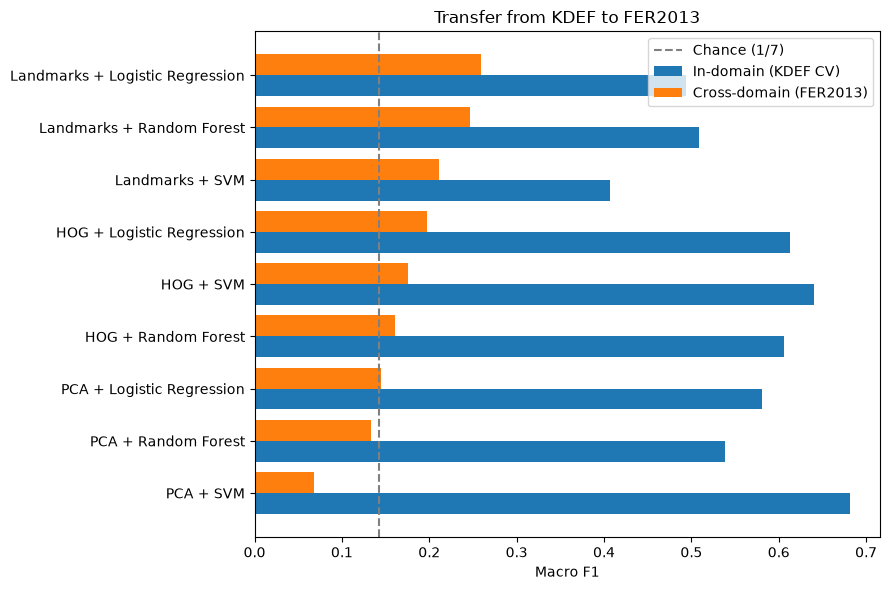

In [28]:
plot_df = transfer.reset_index()
plot_df["Model"] = plot_df["Features"] + " + " + plot_df["Classifier"]
plot_df = plot_df.sort_values("Cross macro F1 (FER2013)")

y = np.arange(len(plot_df))
plt.figure(figsize=(9, 6))
plt.barh(y - 0.2, plot_df["In-domain macro F1 (KDEF CV)"], height=0.4, label="In-domain (KDEF CV)")
plt.barh(y + 0.2, plot_df["Cross macro F1 (FER2013)"], height=0.4, label="Cross-domain (FER2013)")

plt.axvline(1 / 7, color="grey", linestyle="--", label="Chance (1/7)")
plt.yticks(y, plot_df["Model"])
plt.xlabel("Macro F1")

plt.title("Transfer from KDEF to FER2013")
plt.legend()
plt.tight_layout()
plt.savefig("figures/Cross-dataset transfer per feature.png")
plt.show()

In [29]:
# Average over the three classifiers, per feature type
transfer.groupby("Features")[["In-domain macro F1 (KDEF CV)", "Cross macro F1 (FER2013)", "Retained"]].mean().round(2)

,In-domain macro F1 (KDEF CV),Cross macro F1 (FER2013),Retained
Features,,,
HOG,0.62,0.18,0.29
Landmarks,0.47,0.24,0.51
PCA,0.60,0.12,0.20
